<a href="https://colab.research.google.com/github/ahmed-khaled04/bird_image_to_caption/blob/All-Models-notebook/efficientnet_b0_cosine_scheduler.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EfficientNet-B0: cosine learning-rate experiment

This notebook tests **one change** against the saved 20-epoch EfficientNet-B0 run: the AdamW learning rate starts at `1e-4` and decreases by cosine annealing toward `1e-6` over 20 epochs. The model, dataset split, augmentation, optimizer, batch size, and seed stay as before. The scheduler loop is defined here in the notebook; project files in `src/` are unchanged.

Choose **Runtime → Change runtime type → GPU**. Run the setup cells, then the settings, training, and validation cells. The experiment writes to new Google Drive folders, so the fixed-learning-rate baseline remains intact. Select a final model using validation; leave the test cell disabled during comparison.

In [1]:
# 1. Clone the project into Colab. An existing checkout is left untouched.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ahmed-khaled04/bird_image_to_caption.git"
ROOT = Path("/content/bird_image_to_caption")
if not ROOT.exists():
    subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
assert (ROOT / "src").is_dir() and (ROOT / "configs/transfer.yaml").is_file(), ROOT
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project:", ROOT)
subprocess.run(["git", "rev-parse", "--short", "HEAD"], check=True)

Project: /content/bird_image_to_caption


CompletedProcess(args=['git', 'rev-parse', '--short', 'HEAD'], returncode=0)

In [2]:
# 2. Install the project's dependencies. Colab already supplies torch and torchvision.
requirements = [line.strip() for line in (ROOT / "requirements.txt").read_text().splitlines()
                if line.strip() and not line.lstrip().startswith("#")
                and line.strip() not in {"torch", "torchvision"}]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requirements], check=True)
import torch
print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Choose a GPU runtime before full training.")

Torch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


In [3]:
# 3. Mount Drive and make project/models point to persistent checkpoint storage.
from google.colab import drive

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/bird_caption_generator")
DRIVE_MODELS = DRIVE_ROOT / "models"
DRIVE_MODELS.mkdir(parents=True, exist_ok=True)
model_link = ROOT / "models"
if model_link.is_symlink():
    assert model_link.resolve() == DRIVE_MODELS.resolve(), "models points to a different location"
elif model_link.exists():
    contents = list(model_link.iterdir())
    if any(item.name != ".gitkeep" for item in contents):
        raise RuntimeError("Project models/ contains files. Move them to Drive before linking it.")
    for item in contents:
        item.unlink()
    model_link.rmdir()
    model_link.symlink_to(DRIVE_MODELS, target_is_directory=True)
else:
    model_link.symlink_to(DRIVE_MODELS, target_is_directory=True)
print("Checkpoints:", model_link.resolve())

Mounted at /content/drive
Checkpoints: /content/drive/MyDrive/bird_caption_generator/models


In [4]:
from datetime import datetime
from datasets import load_from_disk

DATA_DIR = ROOT / "data/processed"
splits = None

if DATA_DIR.exists():
    try:
        splits = load_from_disk(str(DATA_DIR))
        if not {"train", "validation", "test"}.issubset(splits):
            raise ValueError("A required split is missing")
    except (FileNotFoundError, ValueError, OSError) as error:
        backup = DATA_DIR.with_name(
            f"processed_incomplete_{datetime.now():%Y%m%d_%H%M%S}"
        )
        DATA_DIR.rename(backup)
        print(f"Incomplete data moved to {backup}: {error}")

if splits is None:
    subprocess.run(
        [sys.executable, "-m", "src.cli", "clean", "--no-plots"],
        check=True,
    )
    splits = load_from_disk(str(DATA_DIR))
    assert {"train", "validation", "test"}.issubset(splits)

print({name: len(split) for name, split in splits.items()})
del splits

{'train': 5088, 'validation': 898, 'test': 5794}


## Experiment settings

Use the same 20-epoch configuration as the fixed-rate run. `RUN_NAMES` limits training to fine-tuned EfficientNet-B0. `scheduler` and `eta_min` are recorded in its run configuration and checkpoint metadata. Separate Drive paths prevent the project runner from skipping this new experiment or overwriting the baseline.

In [5]:
# 5. Select the cosine experiment without editing configs/transfer.yaml.
import yaml
from src.transfer import run_configs

CONFIG = yaml.safe_load((ROOT / "configs/transfer.yaml").read_text())
RUN_NAMES = ["efficientnet_b0_finetune"]
LIMIT = None
NUM_WORKERS = 2
CONFIG["defaults"]["epochs"] = 20
CONFIG["defaults"]["num_workers"] = NUM_WORKERS
for item in CONFIG["runs"]:
    if item["name"] == "efficientnet_b0_finetune":
        item["scheduler"] = "cosine"
        item["eta_min"] = 1e-6

TABLE_DIR = DRIVE_ROOT / "outputs/tables_efficientnet_cosine_20"
FIG_DIR = DRIVE_ROOT / "outputs/figures_efficientnet_cosine_20"
RUNS_DIR = TABLE_DIR / "transfer_runs"
TENSORBOARD_DIR = DRIVE_ROOT / "outputs/tensorboard_efficientnet_cosine_20"

runs = run_configs(CONFIG, RUN_NAMES)
assert len(runs) == 1 and runs[0]["epochs"] == 20
print("Run:", runs[0]["name"])
print("Initial LR:", runs[0]["lr"], "final LR target:", runs[0]["eta_min"])
print("Results:", TABLE_DIR)

Run: efficientnet_b0_finetune
Initial LR: 0.0001 final LR target: 1e-06
Results: /content/drive/MyDrive/bird_caption_generator/outputs/tables_efficientnet_cosine_20


In [6]:
# 6. Notebook-only training loop. It reuses the project's model, data, metrics,
# tracking, checkpoint, and report functions; only the per-epoch scheduler is new.
import copy
import gc
import random
import time
import torch
from torch import nn
from datasets import DatasetDict
from src.data.loader import class_names
from src.data.loaders import build_dataloaders
from src.evaluation.classification import evaluate
from src.experiment import (build_model, build_optimizer, count_parameters,
                            load_processed, mode_name, pick_device)
from src.training.checkpoints import (checkpoint_directory, save_checkpoint,
                                      training_metadata)
from src.training.tracking import TensorBoardRun
from src.training.trainer import train_one_epoch
from src.transfer import run_and_save

data = load_processed(DATA_DIR, LIMIT)
checkpoint_dir = checkpoint_directory()

def train_fn(run, test=False, checkpoint_dir=None):
    assert not test, "Choose the final model on validation before using test"
    random.seed(run["seed"])
    torch.manual_seed(run["seed"])
    device = pick_device()
    model = build_model(run).to(device)
    optimizer = build_optimizer(model, run)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=run["epochs"], eta_min=run["eta_min"]
    )
    loss_fn = nn.CrossEntropyLoss()
    loaders = build_dataloaders(
        DatasetDict({name: data[name] for name in ("train", "validation")}),
        image_size=run["image_size"], batch_size=run["batch_size"],
        num_workers=run["num_workers"], seed=run["seed"],
    )
    labels = class_names(data["train"])
    checkpoint_run, labels = training_metadata(
        model, loaders, optimizer, run["epochs"], run_config=run, class_labels=labels
    )
    trainable, total = count_parameters(model)
    print(f"\n=== {run['name']}: {mode_name(run)}, {run['epochs']} epochs on {device}")
    print(f"Trainable weights: {trainable:,} / {total:,}")

    history = []
    best_accuracy, best_epoch, best_state = -1.0, 0, None
    start = time.perf_counter()
    with TensorBoardRun(checkpoint_run, labels, TENSORBOARD_DIR) as tracking:
        for epoch in range(1, run["epochs"] + 1):
            epoch_start = time.perf_counter()
            current_lr = optimizer.param_groups[0]["lr"]
            train_loss, train_accuracy = train_one_epoch(
                model, loaders["train"], loss_fn, optimizer, device
            )
            val = evaluate(model, loaders["validation"], loss_fn, device)
            row = {
                "epoch": epoch, "lr": current_lr,
                "train_loss": train_loss, "train_accuracy": train_accuracy,
                "val_loss": val["loss"], "val_accuracy": val["accuracy"],
            }
            history.append(row)
            tracking.log_epoch(
                row, learning_rates=[group["lr"] for group in optimizer.param_groups],
                validation_top5=val["top5_accuracy"],
                seconds=time.perf_counter() - epoch_start,
            )
            if val["accuracy"] > best_accuracy:
                best_accuracy = val["accuracy"]
                best_epoch = epoch
                best_state = copy.deepcopy(model.state_dict())
            print(f"epoch {epoch}/{run['epochs']} | lr {current_lr:.2e} | "
                  f"train acc {train_accuracy:.3f} | val acc {val['accuracy']:.3f} "
                  f"loss {val['loss']:.3f}")
            scheduler.step()  # after the optimizer updates and validation

        checkpoint_path = save_checkpoint(
            model, checkpoint_run, best_epoch, best_accuracy, labels,
            state_dict=best_state, directory=checkpoint_dir,
        )
        tracking.complete(
            best_epoch, best_accuracy, checkpoint_path,
            seconds=time.perf_counter() - start,
        )

    result = {
        "run": run, "mode": mode_name(run),
        "trainable_params": trainable, "total_params": total,
        "best_val_accuracy": float(best_accuracy), "best_epoch": int(best_epoch),
        "minutes": (time.perf_counter() - start) / 60,
        "device": str(device), "history": history,
        "checkpoint_path": str(checkpoint_path),
        "tensorboard_dir": str(tracking.log_dir),
    }
    return result

for run in runs:
    result = run_and_save(run, train_fn, RUNS_DIR, checkpoint_dir)
    print(run["name"], "best validation accuracy:", f"{result['best_val_accuracy']:.3%}",
          "at epoch", result["best_epoch"])
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

data: train 5088, validation 898, test 5794
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 122MB/s]



=== efficientnet_b0_finetune: fine-tune, 20 epochs on cuda
Trainable weights: 4,263,748 / 4,263,748
TensorBoard: /content/drive/MyDrive/bird_caption_generator/outputs/tensorboard_efficientnet_cosine_20/efficientnet_b0_efficientnet_b0_finetune_20261101T143143626848Z_14fe7d37edbd470a9b0b7c05c860c0bd
epoch 1/20 | lr 1.00e-04 | train acc 0.046 | val acc 0.229 loss 4.507
epoch 2/20 | lr 9.94e-05 | train acc 0.261 | val acc 0.433 loss 3.131
epoch 3/20 | lr 9.76e-05 | train acc 0.450 | val acc 0.551 loss 2.262
epoch 4/20 | lr 9.46e-05 | train acc 0.588 | val acc 0.657 loss 1.738
epoch 5/20 | lr 9.05e-05 | train acc 0.677 | val acc 0.689 loss 1.446
epoch 6/20 | lr 8.55e-05 | train acc 0.727 | val acc 0.739 loss 1.235
epoch 7/20 | lr 7.96e-05 | train acc 0.773 | val acc 0.756 loss 1.109
epoch 8/20 | lr 7.30e-05 | train acc 0.809 | val acc 0.768 loss 1.005
epoch 9/20 | lr 6.58e-05 | train acc 0.828 | val acc 0.781 loss 0.947
epoch 10/20 | lr 5.82e-05 | train acc 0.857 | val acc 0.783 loss 0.921


=== transfer learning vs scratch (best validation accuracy)
run                efficientnet_b0_finetune
encoder                     efficientnet_b0
mode                              fine-tune
trainable_params_M                   4.2637
total_params_M                       4.2637
lr                                   0.0001
epochs                                   20
best_epoch                               12
best_val_accuracy                    0.8029
minutes                             21.5208
minutes_per_epoch                     1.076
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures_efficientnet_cosine_20/transfer_learning_curves.png
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures_efficientnet_cosine_20/transfer_validation_scores.png


,encoder,mode,trainable_params_M,total_params_M,lr,epochs,best_epoch,best_val_accuracy,minutes,minutes_per_epoch
run,,,,,,,,,,
efficientnet_b0_finetune,efficientnet_b0,fine-tune,4.263748,4.263748,0.0001,20,12,0.802895,21.52076,1.076038


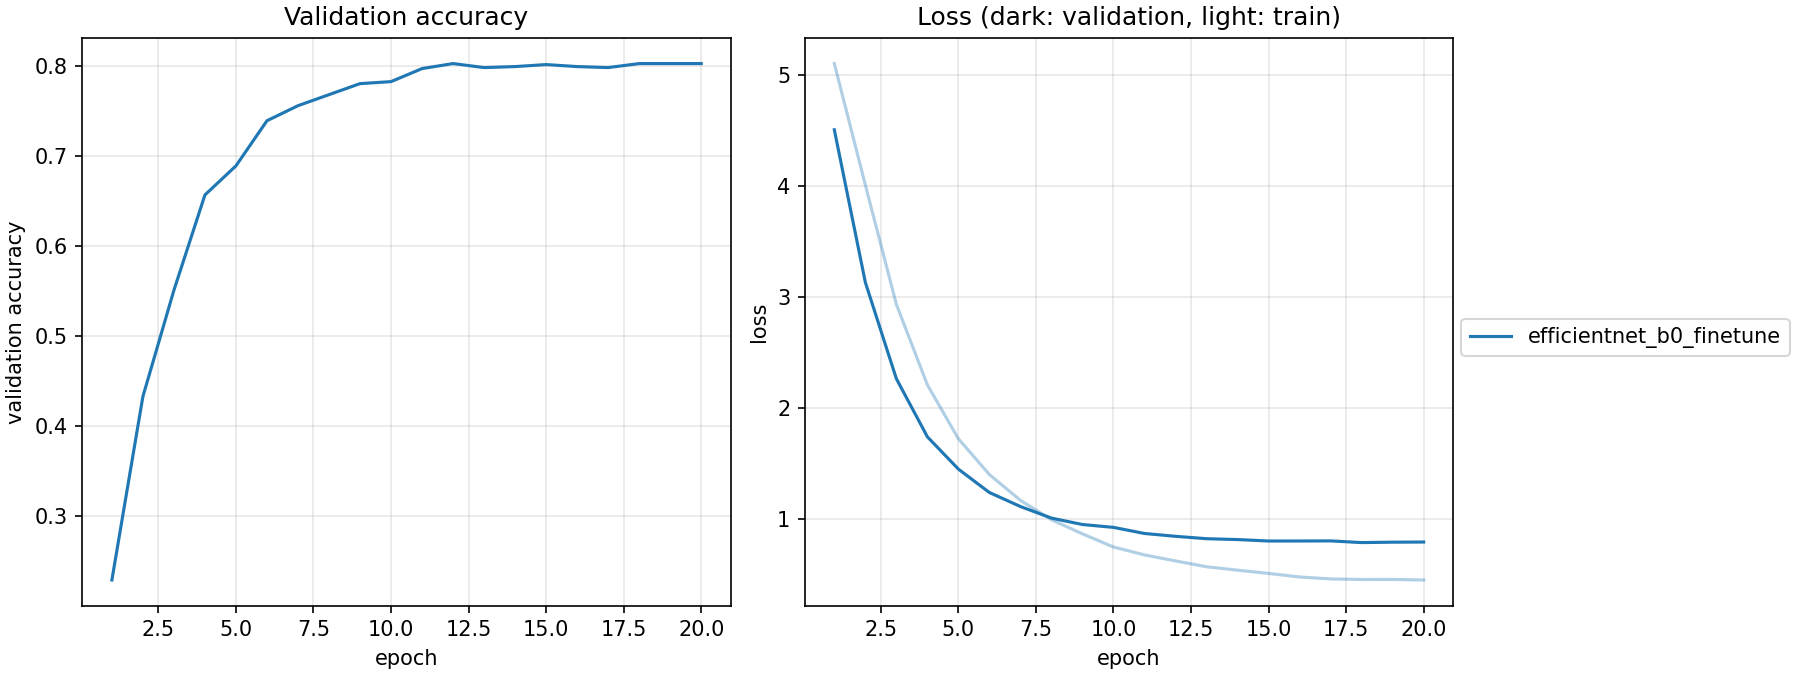

In [7]:
# 7. Save the same project comparison and training-curve figures as the baseline.
from IPython.display import Image, display
from src.transfer import report

FIG_DIR.mkdir(parents=True, exist_ok=True)
comparison = report(CONFIG, TABLE_DIR, FIG_DIR, RUNS_DIR)
display(comparison.sort_values("best_val_accuracy", ascending=False))
display(Image(filename=str(FIG_DIR / "transfer_learning_curves.png")))

In [8]:
# 8. Re-evaluate the saved best-epoch checkpoint on VALIDATION only.
from src.evaluation.report import run_evaluation

EVAL_TABLE_DIR = TABLE_DIR / "evaluation"
EVAL_FIG_DIR = FIG_DIR / "evaluation"
selected_runs = [run["name"] for run in runs]
validation_table = run_evaluation(
    DATA_DIR, RUNS_DIR, checkpoint_dir, EVAL_TABLE_DIR, EVAL_FIG_DIR,
    selected_runs=selected_runs, test_run=None, num_workers=NUM_WORKERS, device="auto",
)
display(validation_table[["encoder", "mode", "accuracy", "top5_accuracy",
                          "precision_macro", "recall_macro", "f1_macro", "train_minutes"]])
print("Validation report:", EVAL_TABLE_DIR / "validation_comparison.csv")

saved /content/drive/MyDrive/bird_caption_generator/outputs/figures_efficientnet_cosine_20/evaluation/validation_efficientnet_b0_finetune_top_confusions.png
validated efficientnet_b0_finetune: accuracy 0.803, macro F1 0.791

=== validation comparison (all saved best-epoch checkpoints)
                                  encoder       mode  best_epoch  accuracy  top5_accuracy  precision_macro  recall_macro  f1_macro  train_minutes
run                                                                                                                                              
efficientnet_b0_finetune  efficientnet_b0  fine-tune          12     0.803          0.953            0.816           0.8     0.791         21.521


,encoder,mode,accuracy,top5_accuracy,precision_macro,recall_macro,f1_macro,train_minutes
run,,,,,,,,
efficientnet_b0_finetune,efficientnet_b0,fine-tune,0.802895,0.953229,0.816073,0.7995,0.790906,21.52076


Validation report: /content/drive/MyDrive/bird_caption_generator/outputs/tables_efficientnet_cosine_20/evaluation/validation_comparison.csv


In [9]:
# 9. Compare the cosine run with the earlier fixed-1e-4, 20-epoch run.
import json
import pandas as pd

baseline_dir = DRIVE_ROOT / "outputs/tables_efficientnet_20"
name = "efficientnet_b0_finetune"
baseline_json = json.loads((baseline_dir / "transfer_runs" / f"{name}.json").read_text())
cosine_json = json.loads((RUNS_DIR / f"{name}.json").read_text())
baseline_eval = pd.read_csv(
    baseline_dir / "evaluation/validation_comparison.csv", index_col="run"
).loc[name]
cosine_eval = validation_table.loc[name]
comparison_rows = pd.DataFrame([
    {"training": "fixed LR", "epochs": baseline_json["run"]["epochs"],
     "best_epoch": baseline_json["best_epoch"], "accuracy": baseline_eval["accuracy"],
     "f1_macro": baseline_eval["f1_macro"], "minutes": baseline_json["minutes"]},
    {"training": "cosine LR", "epochs": cosine_json["run"]["epochs"],
     "best_epoch": cosine_json["best_epoch"], "accuracy": cosine_eval["accuracy"],
     "f1_macro": cosine_eval["f1_macro"], "minutes": cosine_json["minutes"]},
])
comparison_path = TABLE_DIR / "cosine_vs_fixed_20.csv"
comparison_rows.to_csv(comparison_path, index=False)
display(comparison_rows)
print("Saved:", comparison_path)

,training,epochs,best_epoch,accuracy,f1_macro,minutes
0,fixed LR,20,19,0.808463,0.796399,18.942683
1,cosine LR,20,12,0.802895,0.790906,21.520760


Saved: /content/drive/MyDrive/bird_caption_generator/outputs/tables_efficientnet_cosine_20/cosine_vs_fixed_20.csv


## Final test: leave disabled while comparing experiments

Set `FINAL_TEST_RUN` only after selecting the final encoder using validation results. The comparison above does not touch the test split.

In [10]:
# 10. Optional final test for the selected cosine model only.
FINAL_TEST_RUN = None
if FINAL_TEST_RUN is not None:
    assert FINAL_TEST_RUN in selected_runs
    run_evaluation(
        DATA_DIR, RUNS_DIR, checkpoint_dir,
        EVAL_TABLE_DIR / "final_test", EVAL_FIG_DIR / "final_test",
        selected_runs=[FINAL_TEST_RUN], test_run=FINAL_TEST_RUN,
        num_workers=NUM_WORKERS, device="auto",
    )
else:
    print("Test split untouched.")

Test split untouched.


## Saved evidence

Google Drive retains the new model checkpoint under `bird_caption_generator/models/`, the run JSON and CSV reports under `outputs/tables_efficientnet_cosine_20/`, plots under `outputs/figures_efficientnet_cosine_20/`, and learning-rate curves under `outputs/tensorboard_efficientnet_cosine_20/`. The fixed-rate 20-epoch results remain in their original folders. Copy reviewed figures and tables into the project documentation when ready.